In [25]:
from pathlib import Path

import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Polygon
import csv

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INPUT_DIR = PROJECT_ROOT / "data" / "input"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

In [2]:
print("смотрим статистику по зонам")
zone_stats = pd.read_csv(PROCESSED_DIR / "zone_stats.csv")
zone_stats

смотрим статистику по зонам


,zone,res_buildings,res_floor_m2,res_share,work_buildings,work_floor_m2,work_points,work_share,unclassified_buildings,res_levels_known_pct,work_levels_known_pct
0,Z01,19,87571,0.0177,13,44495,13,0.0097,14,100,85
1,Z02,115,2399483,0.4846,144,1740053,576,0.3791,67,97,69
2,Z04,2,33311,0.0067,32,329461,54,0.0718,258,100,78
3,Z05,68,765232,0.1545,54,252323,133,0.0550,59,100,76
4,Z06,98,780414,0.1576,47,348747,90,0.0760,134,46,79
5,Z07,149,784737,0.1585,118,691118,301,0.1506,37,99,87
6,Z08,47,101160,0.0204,24,1183948,8,0.2579,52,100,92


In [8]:
calibration_df = pd.read_csv(INPUT_DIR / 'calibration.csv')
points_df = pd.read_csv(INPUT_DIR / 'points.csv')
area_df = pd.read_csv(INPUT_DIR / 'area.csv')
flows_df = pd.read_csv(INPUT_DIR / 'flows_template.csv')

area_df.head(10)

,номер,широта,долгота
0,1,55.917475,37.487362
1,2,55.922627,37.528873
2,3,55.924067,37.528150
3,4,55.924441,37.527962
4,5,55.925795,37.527279
5,6,55.927523,37.526408
6,7,55.929286,37.525424
7,8,55.930976,37.524659
8,9,55.931595,37.524344
9,10,55.932703,37.523782


In [28]:
points_df.drop_duplicates(subset=['широта','долгота'])

,id,место,широта,долгота,направление
0,P01A,Дирижабельная улица,55.94101,37.50945,на север
2,P02A,Лихачёвский проспект у Лихачёвского проезда,55.91884,37.49420,"на юг, в сторону Москвы"
4,P03A,"Московская улица у станции «Водники», сразу за...",55.95392,37.51604,"на северо-восток, из города"
6,P04A,Новый бульвар между Спортивной улицей и улицей...,55.93824,37.50097,на восток
8,P05A,Институтский переулок,55.93083,37.51797,на восток
10,P06A,Долгопрудненское шоссе у Лихачёвского проезда,55.92266,37.52498,"на восток, в сторону Москвы"
12,P07A,Лихачёвское шоссе,55.94433,37.49166,на север
14,P08A,Лихачёвский проспект у ТЦ «Город»,55.93613,37.49295,"на юг, в сторону Москвы"
16,P09A,проспект Ракетостроителей между Лётной и Дириж...,55.93321,37.50776,на восток
18,P10A,Первомайская улица у остановки «МФТИ»,55.92998,37.52135,на юг


In [ ]:
calibration_df.head(5)

,id,07:00-08:00,08:00-09:00
0,P02A,3188,3474
1,P02B,1334,1878
2,P08A,2221,2291
3,P14B,718,1100


Как найти точки выезда

In [32]:
import pandas as pd

pts = points_df.drop_duplicates(subset=["широта", "долгота"])

def border(lat, lon):
    point = gpd.GeoSeries.from_xy([lon], [lat], crs=4326).to_crs(32637).iloc[0]
    return area.boundary.distance(point)

pts["м_до_границы"] = [border(la, lo) for la, lo in zip(pts["широта"], pts["долгота"])]
pts.sort_values("м_до_границы")

C:\Users\Mishania\AppData\Local\Temp\ipykernel_13376\2559276510.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pts["м_до_границы"] = [border(la, lo) for la, lo in zip(pts["широта"], pts["долгота"])]


,id,место,широта,долгота,направление,м_до_границы
24,P13A,Лихачёвский проезд,55.92138,37.51737,на восток,19.468298
2,P02A,Лихачёвский проспект у Лихачёвского проезда,55.91884,37.49420,"на юг, в сторону Москвы",55.999535
10,P06A,Долгопрудненское шоссе у Лихачёвского проезда,55.92266,37.52498,"на восток, в сторону Москвы",56.031531
4,P03A,"Московская улица у станции «Водники», сразу за...",55.95392,37.51604,"на северо-восток, из города",60.265943
18,P10A,Первомайская улица у остановки «МФТИ»,55.92998,37.52135,на юг,227.703874
26,P14A,Лихачёвский проспект у Промышленного проезда,55.92671,37.49297,"на юг, в сторону Москвы",268.795937
8,P05A,Институтский переулок,55.93083,37.51797,на восток,406.372028
14,P08A,Лихачёвский проспект у ТЦ «Город»,55.93613,37.49295,"на юг, в сторону Москвы",413.511148
20,P11A,улица Циолковского,55.93673,37.51372,на север,481.717832
0,P01A,Дирижабельная улица,55.94101,37.50945,на север,608.776413


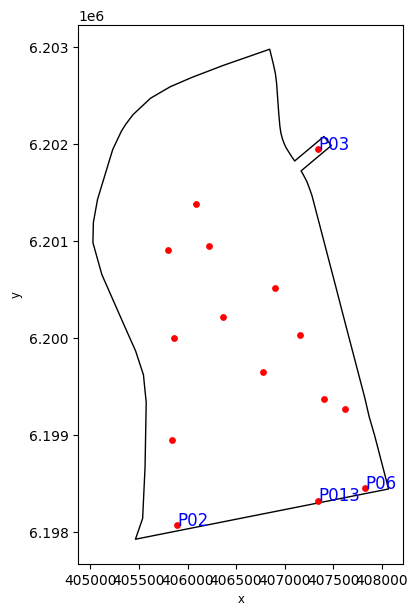

In [33]:
fig, ax = plt.subplots(figsize=(7, 7))

area_poly = gpd.GeoSeries(
    [Polygon(zip(area_df["долгота"], area_df["широта"]))], crs=4326
).to_crs(32637).iloc[0]

gpd.GeoSeries([area_poly]).plot(ax=ax, facecolor="none", edgecolor="black")      # граница

GATES = {
    "P02": (55.91884, 37.49420),
    "P03": (55.95392, 37.51604),
    "P06": (55.92266, 37.52498),
    "P013": (55.92138, 37.51737)
}

gate_points = {}
for name, (lat, lon) in GATES.items():
    gate_points[name] = gpd.GeoSeries.from_xy([lon], [lat], crs=4326).to_crs(32637).iloc[0]

x = gpd.GeoSeries.from_xy(pts["долгота"], pts["широта"], crs=4326).to_crs(32637)
x.plot(ax=ax, color="red", markersize=15)                                   # все точки
for name, p in gate_points.items():                                         # ворота
    ax.annotate(name, (p.x, p.y), color="blue", fontsize=12)
plt.show()

Визуализации

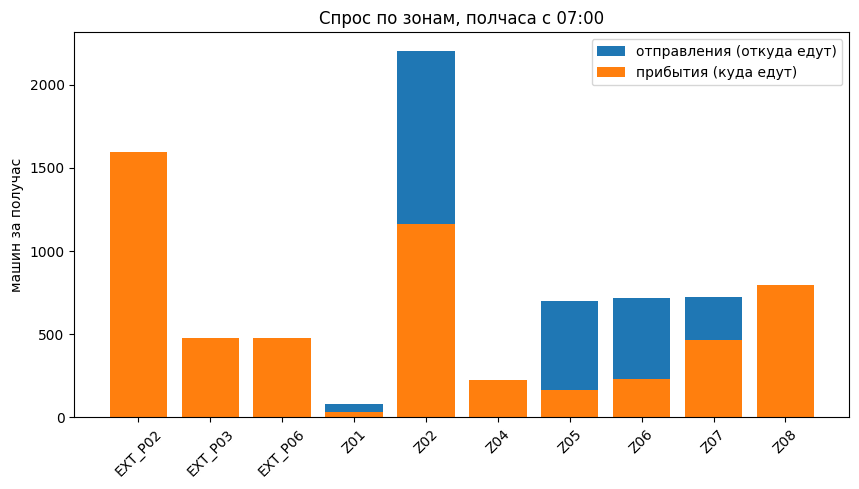

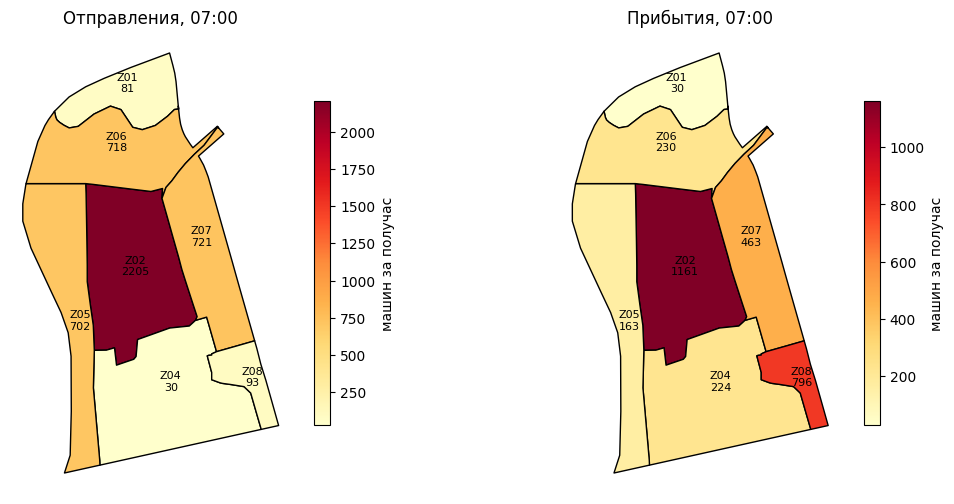

In [ ]:
import json
import matplotlib.pyplot as plt
 
# ---------------- НАСТРОЙКИ ----------------
PERIOD = "07:00"            # какие полчаса показать: 07:00, 07:30, 08:00 или 08:30
ZONES_FILE = PROCESSED_DIR / "zones_primary.geojson"
ZONE_COLUMN = "zone_id"
 

with (PROCESSED_DIR / "periods.json").open(encoding="utf-8") as f:
    periods = json.load(f)
departures = periods[PERIOD]["departures"]
arrivals = periods[PERIOD]["arrivals"]
names = list(departures) 
 

x = range(len(names))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i for i in x], [departures[n] for n in names],
       label="отправления (откуда едут)")
ax.bar([i for i in x], [arrivals[n] for n in names],
       label="прибытия (куда едут)")
ax.set_xticks(list(x))
ax.set_xticklabels(names, rotation=45)
ax.set_ylabel("машин за получас")
ax.set_title(f"Спрос по зонам, полчаса с {PERIOD}")
ax.legend()

 
zones = gpd.read_file(ZONES_FILE)
column = ZONE_COLUMN
zones["zone"] = zones[column].astype(str)
zones["departures"] = zones["zone"].map(departures)
zones["arrivals"] = zones["zone"].map(arrivals)
 
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, col, title in [(axes[0], "departures", "Отправления"),
                           (axes[1], "arrivals", "Прибытия")]:
    zones.plot(column=col, cmap="YlOrRd", legend=True, edgecolor="black", ax=ax,
                   legend_kwds={"label": "машин за получас", "shrink": 0.7})
        
    for _, row in zones.iterrows():
        p = row.geometry.representative_point()
        ax.annotate(f"{row['zone']}\n{row[col]:.0f}", (p.x, p.y),
                    ha="center", fontsize=8)
    ax.set_title(f"{title}, {PERIOD}")
    ax.set_axis_off()
    
 
plt.show()

In [12]:
HSE_DIR = PROJECT_ROOT / "data" / "hse_data"

mo = gpd.read_file(HSE_DIR / "Муниципальные_образования_верхнего_уровня_России.shp")
mo = mo[mo["region"].isin(["Московская область", "г. Москва"])].to_crs(32637)
c = mo.geometry.centroid

# ворота: координаты из points.csv
gates = gpd.GeoSeries.from_xy([37.49420, 37.51604, 37.52498],
                              [55.91884, 55.95392, 55.92266],
                              crs=4326).to_crs(32637)
for name, g in zip(["P02", "P03", "P06"], gates):
    mo["км_до_" + name] = (c.distance(g) / 1000).round(1)

print(mo[["name", "pop", "км_до_P02", "км_до_P03", "км_до_P06"]]
      .sort_values("км_до_P02").head(25))

                                          name     pop  км_до_P02  км_до_P03  \
1285                              Долгопрудный  117778        3.6        1.0   
241               муниципальный округ Северный   38529        3.7        3.0   
693            муниципальный округ Дмитровский   93321        3.7        7.0   
1008             муниципальный округ Лианозово   85867        5.1        6.8   
827      муниципальный округ Западное Дегунино   84273        5.4        9.1   
1199               муниципальный округ Ховрино   88915        5.5        9.6   
518     муниципальный округ Восточное Дегунино   98923        6.1        8.8   
833           муниципальный округ Левобережный   54648        6.2       10.3   
1348                                     Химки  257757        6.8        8.4   
493        муниципальный округ Бескудниковский   79607        6.8        9.9   
841           муниципальный округ Алтуфьевский   57601        7.1        9.3   
1202               муниципальный округ К

In [13]:
mo[["name", "pop", "км_до_P02", "км_до_P03", "км_до_P06"]].sort_values("км_до_P02").head(25)

,name,pop,км_до_P02,км_до_P03,км_до_P06
1285,Долгопрудный,117778,3.6,1.0,3.4
241,муниципальный округ Северный,38529,3.7,3.0,1.8
693,муниципальный округ Дмитровский,93321,3.7,7.0,3.5
1008,муниципальный округ Лианозово,85867,5.1,6.8,3.7
827,муниципальный округ Западное Дегунино,84273,5.4,9.1,5.6
1199,муниципальный округ Ховрино,88915,5.5,9.6,6.4
518,муниципальный округ Восточное Дегунино,98923,6.1,8.8,5.4
833,муниципальный округ Левобережный,54648,6.2,10.3,7.3
1348,Химки,257757,6.8,8.4,8.7
493,муниципальный округ Бескудниковский,79607,6.8,9.9,6.4


In [15]:
area_df

,номер,широта,долгота
0,1,55.917475,37.487362
1,2,55.922627,37.528873
2,3,55.924067,37.528150
3,4,55.924441,37.527962
4,5,55.925795,37.527279
...,...,...,...
58,59,55.932699,37.488086
59,60,55.930151,37.488644
60,61,55.924165,37.488687
61,62,55.919403,37.488472


In [ ]:
from shapely.geometry import Polygon
import csv

# Точки замера на въездах (широта, долгота) из points.csv
GATES = {
    "P02": (55.91884, 37.49420),
    "P03": (55.95392, 37.51604),
    "P06": (55.92266, 37.52498),
}

MAX_KM = 15
MIN_KM = 1.0

# Читаем точки границы: (долгота, широта)
points = []
with open(INPUT_DIR / 'area.csv', encoding="utf-8-sig") as f:
    for row in csv.DictReader(f):
        points.append((float(row["долгота"]), float(row["широта"])))


area = gpd.GeoSeries([Polygon(points)], crs=4326).to_crs(32637).iloc[0]

gate_points = {}
for name, (lat, lon) in GATES.items():
    gate_points[name] = gpd.GeoSeries.from_xy([lon], [lat], crs=4326).to_crs(32637).iloc[0]


for name, point in gate_points.items():
    inside = "внутри" if area.contains(point) else "ворота снаружи"
    meters = area.boundary.distance(point)
    print(f"{name}: {inside} области, {meters:.0f} м до границы")

P02: внутри области, 56 м до границы
P03: внутри области, 60 м до границы
P06: внутри области, 56 м до границы


In [17]:
mo = mo[mo["region"].isin(["Московская область", "г. Москва"])]
mo = mo.to_crs(32637)

# Центр каждого образования
mo["center"] = mo.geometry.centroid

# Убираем те, чей центр внутри нашей области
mo = mo[~mo["center"].within(area)].copy()
print("Образований рядом:", len(mo))

Образований рядом: 208


In [18]:
for name, point in gate_points.items():
    mo["km_" + name] = mo["center"].distance(point) / 1000

dist_columns = ["km_P02", "km_P03", "km_P06"]

# Ближайшие ворота и расстояние до них
mo["km"] = mo[dist_columns].min(axis=1)
mo["gate"] = mo[dist_columns].idxmin(axis=1).str.replace("km_", "")

# Оставляем только те, что не дальше MAX_KM
mo = mo[mo["km"] <= MAX_KM].copy()
mo[["name", "pop", "gate", "km"]].sort_values("km").head(15)

,name,pop,gate,km
241,муниципальный округ Северный,38529,P06,1.784808
693,муниципальный округ Дмитровский,93321,P06,3.488786
1008,муниципальный округ Лианозово,85867,P06,3.651405
518,муниципальный округ Восточное Дегунино,98923,P06,5.382856
827,муниципальный округ Западное Дегунино,84273,P02,5.407775
1199,муниципальный округ Ховрино,88915,P02,5.539266
841,муниципальный округ Алтуфьевский,57601,P06,6.011268
982,муниципальный округ Бибирево,160248,P06,6.034983
833,муниципальный округ Левобережный,54648,P02,6.184612
493,муниципальный округ Бескудниковский,79607,P06,6.404764


In [20]:
mo.head(10)

,db_j4c1v_h,oktmo,oktmo_num,region,type,name,admcen,note,fo,pop,...,geometry,км_до_P02,км_до_P03,км_до_P06,center,km_P02,km_P03,km_P06,km,gate
241,1189,45363000,45363000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Северный,None,None,Центральный,38529,...,"POLYGON ((409719.969 6196923.653, 408530.498 6...",3.7,3.0,1.8,POINT (409232.079 6199554.517),3.652992,3.047438,1.784808,1.784808,P06
300,1190,45364000,45364000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Южное Медведково,None,None,Центральный,85739,...,"POLYGON ((413666.397 6194210.852, 413926.201 6...",10.1,11.5,8.7,POINT (414575.055 6193006.305),10.050626,11.498587,8.673512,8.673512,P06
493,1161,45335000,45335000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Бескудниковский,None,None,Центральный,79607,...,"POLYGON ((410652.687 6190833.247, 410647.339 6...",6.8,9.9,6.4,POINT (409433.29 6192254.812),6.808558,9.913541,6.404764,6.404764,P06
516,1162,45336000,45336000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Войковский,None,None,Центральный,70623,...,"POLYGON ((406370.644 6188954.542, 406400.81 61...",10.2,14.1,10.8,POINT (405853.284 6187883.023),10.188128,14.140957,10.754248,10.188128,P02
518,1163,45337000,45337000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Восточное Дегунино,None,None,Центральный,98923,...,"POLYGON ((410395.795 6194464.295, 410395.378 6...",6.1,8.8,5.4,POINT (409959.012 6193512.348),6.107982,8.829614,5.382856,5.382856,P06
520,1164,45338000,45338000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Головинский,None,None,Центральный,103508,...,"POLYGON ((409553.923 6190153.794, 409492.498 6...",7.8,11.6,8.2,POINT (406838.825 6190328.231),7.800290,11.628032,8.186273,7.800290,P02
524,1195,45369000,45369000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Северное Тушино,None,None,Центральный,165736,...,"POLYGON ((402275.965 6193517.08, 402320.914 61...",7.6,11.6,9.1,POINT (401625.338 6191806.172),7.580844,11.639935,9.091541,7.580844,P02
693,1165,45339000,45339000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Дмитровский,None,None,Центральный,93321,...,"POLYGON ((408530.498 6196709.357, 408575.236 6...",3.7,7.0,3.5,POINT (407966.59 6194968.751),3.731034,7.004467,3.488786,3.488786,P06
827,1166,45340000,45340000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Западное Дегунино,None,None,Центральный,84273,...,"POLYGON ((405953.089 6195140.475, 406038.145 6...",5.4,9.1,5.6,POINT (407348.716 6192862.673),5.407775,9.082682,5.612409,5.407775,P02
830,1167,45341000,45341000,г. Москва,внутригородская территория (внутригородское му...,муниципальный округ Коптево,None,None,Центральный,101885,...,"POLYGON ((408553.635 6186107.901, 408474.839 6...",9.9,13.6,10.1,POINT (407865.633 6188399.778),9.870249,13.555676,10.055017,9.870249,P02


In [ ]:
mo["weight"] = mo["pop"] / mo["km"].clip(lower=MIN_KM) ** 2

summary = mo.groupby("gate")[["pop", "weight"]].sum()
summary = summary.reindex(["P02", "P03", "P06"]).fillna(0)


summary["доля"] = summary["weight"] / summary["weight"].sum()
summary["относительно_P02"] = summary["weight"] / summary.loc["P02", "weight"]
summary.round(3)

,pop,weight,доля,относительно_P02
gate,,,,
P02,1749818,25331.948,0.326,1.000
P03,362339,3750.923,0.048,0.148
P06,1847674,48632.361,0.626,1.920


In [22]:
mo[["name", "pop", "gate", "km", "weight"]].sort_values("weight", ascending=False).head(20)

,name,pop,gate,km,weight
241,муниципальный округ Северный,38529,P06,1.784808,12094.964492
693,муниципальный округ Дмитровский,93321,P06,3.488786,7667.092070
1008,муниципальный округ Лианозово,85867,P06,3.651405,6440.301155
1348,Химки,257757,P02,6.839204,5510.606182
982,муниципальный округ Бибирево,160248,P06,6.034983,4399.876617
518,муниципальный округ Восточное Дегунино,98923,P06,5.382856,3414.065294
1199,муниципальный округ Ховрино,88915,P02,5.539266,2897.814886
524,муниципальный округ Северное Тушино,165736,P02,7.580844,2883.910529
827,муниципальный округ Западное Дегунино,84273,P02,5.407775,2881.716565
1066,муниципальный округ Отрадное,185459,P06,8.254330,2721.975860
